# Flight Delay Prediction Using Machine Learning

## Project Objective

The objective of this project is to develop a machine learning classification
system that predicts whether a flight is likely to be delayed by more than
15 minutes.

Five machine learning algorithms are implemented and compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. XGBoost


## 1. Import Required Libraries
Import the Python libraries required for data analysis, visualization, preprocessing, model building, and evaluation.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset
Load the flights dataset into a Pandas DataFrame so that it can be explored and prepared for machine learning.

In [8]:
import pandas as pd

DATA_PATH = r"C:\Users\KARTHIK\Downloads\flight-delay-prediction-mlops-code\data\flights.csv"

df = pd.read_csv(
    DATA_PATH,
    nrows=500000
)

df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Display the Dataset
Display the first few rows to understand the structure, columns, and type of information contained in the dataset.

In [9]:
df.head()

,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Check Dataset Shape
Check the number of rows and columns to understand the size and dimensionality of the dataset.

In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 500000
Number of columns: 31


## 5. Dataset Columns

### What we did
We display all column names.

In [11]:
for i, column in enumerate(df.columns, 1):
    print(i, ":", column)

1 : YEAR
2 : MONTH
3 : DAY
4 : DAY_OF_WEEK
5 : AIRLINE
6 : FLIGHT_NUMBER
7 : TAIL_NUMBER
8 : ORIGIN_AIRPORT
9 : DESTINATION_AIRPORT
10 : SCHEDULED_DEPARTURE
11 : DEPARTURE_TIME
12 : DEPARTURE_DELAY
13 : TAXI_OUT
14 : WHEELS_OFF
15 : SCHEDULED_TIME
16 : ELAPSED_TIME
17 : AIR_TIME
18 : DISTANCE
19 : WHEELS_ON
20 : TAXI_IN
21 : SCHEDULED_ARRIVAL
22 : ARRIVAL_TIME
23 : ARRIVAL_DELAY
24 : DIVERTED
25 : CANCELLED
26 : CANCELLATION_REASON
27 : AIR_SYSTEM_DELAY
28 : SECURITY_DELAY
29 : AIRLINE_DELAY
30 : LATE_AIRCRAFT_DELAY
31 : WEATHER_DELAY


## 6. Dataset Information
Examine column names, data types, and non-null values to identify the structure and possible preprocessing requirements.

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 31 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   YEAR                 500000 non-null  int64  
 1   MONTH                500000 non-null  int64  
 2   DAY                  500000 non-null  int64  
 3   DAY_OF_WEEK          500000 non-null  int64  
 4   AIRLINE              500000 non-null  str    
 5   FLIGHT_NUMBER        500000 non-null  int64  
 6   TAIL_NUMBER          496250 non-null  str    
 7   ORIGIN_AIRPORT       500000 non-null  str    
 8   DESTINATION_AIRPORT  500000 non-null  str    
 9   SCHEDULED_DEPARTURE  500000 non-null  int64  
 10  DEPARTURE_TIME       483584 non-null  float64
 11  DEPARTURE_DELAY      483584 non-null  float64
 12  TAXI_OUT             483296 non-null  float64
 13  WHEELS_OFF           483296 non-null  float64
 14  SCHEDULED_TIME       499999 non-null  float64
 15  ELAPSED_TIME         482052 

## 6. Statistical Summary
Generate descriptive statistics for numerical columns to understand their distributions, ranges, and central tendencies.

In [13]:
df.describe()

,YEAR,MONTH,DAY,DAY_OF_WEEK,FLIGHT_NUMBER,SCHEDULED_DEPARTURE,DEPARTURE_TIME,DEPARTURE_DELAY,TAXI_OUT,WHEELS_OFF,...,SCHEDULED_ARRIVAL,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
count,500000.0,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,483584.000000,483584.000000,483296.000000,483296.000000,...,500000.000000,482841.000000,482052.000000,500000.000000,500000.000000,102299.000000,102299.000000,102299.000000,102299.000000,102299.000000
mean,2015.0,1.060064,14.995424,4.006006,2263.467272,1323.040278,1332.957112,10.122653,16.487865,1356.717620,...,1506.505554,1493.390449,6.229542,0.002248,0.033648,13.476202,0.067635,17.999814,22.902130,3.321225
std,0.0,0.237606,9.320111,2.012339,1803.531769,468.226703,479.873381,37.720225,9.671997,479.846599,...,483.438045,503.047636,40.494655,0.047360,0.180322,25.461451,2.027208,45.863346,41.711079,21.899448
min,2015.0,1.000000,1.000000,1.000000,1.000000,5.000000,1.000000,-48.000000,1.000000,1.000000,...,1.000000,1.000000,-82.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2015.0,1.000000,7.000000,2.000000,759.000000,925.000000,930.000000,-5.000000,11.000000,946.000000,...,1124.000000,1117.000000,-13.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2015.0,1.000000,15.000000,4.000000,1732.000000,1320.000000,1328.000000,-1.000000,14.000000,1342.000000,...,1525.000000,1522.000000,-4.000000,0.000000,0.000000,4.000000,0.000000,2.000000,4.000000,0.000000
75%,2015.0,1.000000,23.000000,6.000000,3484.000000,1720.000000,1729.000000,9.000000,19.000000,1742.000000,...,1914.000000,1915.000000,10.000000,0.000000,0.000000,18.000000,0.000000,18.000000,29.000000,0.000000
max,2015.0,2.000000,31.000000,7.000000,9793.000000,2359.000000,2400.000000,1988.000000,177.000000,2400.000000,...,2359.000000,2400.000000,1971.000000,1.000000,1.000000,830.000000,241.000000,1971.000000,948.000000,1116.000000


## 8. Categorical Variable Summary

### What we did
We examine the categorical columns.

### Why we did it
Categorical variables such as airline and airport codes cannot be directly
used by most machine learning algorithms and will later require encoding.

In [14]:
df.describe(include="object")

,AIRLINE,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,CANCELLATION_REASON
count,500000,496250,500000,500000,16824
unique,14,4412,313,313,4
top,WN,N475HA,ATL,ATL,B
freq,106253,405,31332,31392,10630


## 9. Missing Value Analysis

### What we did
We calculate the number and percentage of missing values in every column.

### Why we did it
Machine learning algorithms generally cannot directly process missing
values. We therefore need to understand where missing values occur before
choosing an appropriate preprocessing strategy.

In [15]:
missing = df.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

print("Missing values:")
print(missing)

Missing values:
CANCELLATION_REASON    483176
SECURITY_DELAY         397701
AIR_SYSTEM_DELAY       397701
LATE_AIRCRAFT_DELAY    397701
WEATHER_DELAY          397701
AIRLINE_DELAY          397701
ARRIVAL_DELAY           17948
ELAPSED_TIME            17948
AIR_TIME                17948
TAXI_IN                 17159
WHEELS_ON               17159
ARRIVAL_TIME            17159
TAXI_OUT                16704
WHEELS_OFF              16704
DEPARTURE_DELAY         16416
DEPARTURE_TIME          16416
TAIL_NUMBER              3750
SCHEDULED_TIME              1
dtype: int64


In [16]:
missing_percentage = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

print("\nMissing value percentage:")
print(
    missing_percentage[
        missing_percentage > 0
    ]
)


Missing value percentage:
CANCELLATION_REASON    96.6352
LATE_AIRCRAFT_DELAY    79.5402
WEATHER_DELAY          79.5402
AIRLINE_DELAY          79.5402
AIR_SYSTEM_DELAY       79.5402
SECURITY_DELAY         79.5402
ELAPSED_TIME            3.5896
AIR_TIME                3.5896
ARRIVAL_DELAY           3.5896
WHEELS_ON               3.4318
TAXI_IN                 3.4318
ARRIVAL_TIME            3.4318
WHEELS_OFF              3.3408
TAXI_OUT                3.3408
DEPARTURE_TIME          3.2832
DEPARTURE_DELAY         3.2832
TAIL_NUMBER             0.7500
SCHEDULED_TIME          0.0002
dtype: float64


## 10. Visualization of Missing Values

We visualize columns containing missing observations.

A graph makes it easier to identify variables with a particularly high
proportion of missing values.


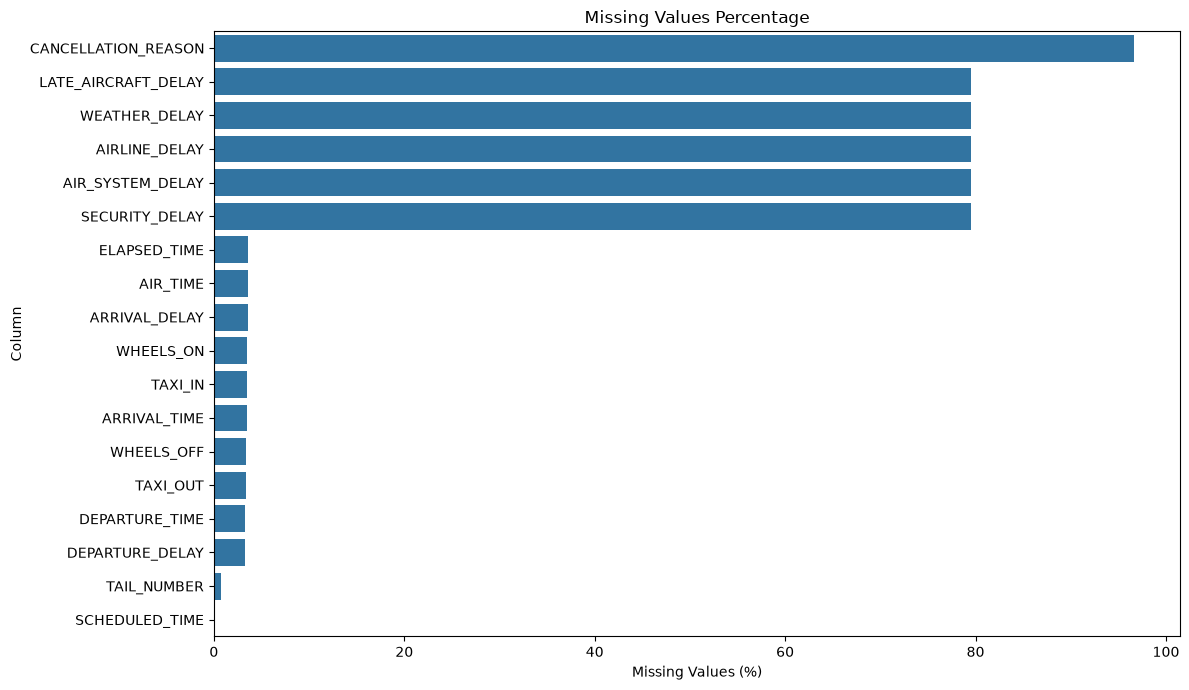

In [17]:
plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing_percentage[missing_percentage > 0].values,
    y=missing_percentage[missing_percentage > 0].index
)

plt.title("Missing Values Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

plt.tight_layout()
plt.show()

## 11. Duplicate Record Analysis

We check whether identical rows occur more than once.


In [18]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [19]:
df = df.drop_duplicates()

print("Dataset shape after duplicate removal:", df.shape)

Dataset shape after duplicate removal: (500000, 31)


## 12. Target Variable Analysis

We examine `ARRIVAL_DELAY`, which represents the arrival delay of the flight.


In [20]:
print(df["ARRIVAL_DELAY"].describe())

count    482052.000000
mean          6.229542
std          40.494655
min         -82.000000
25%         -13.000000
50%          -4.000000
75%          10.000000
max        1971.000000
Name: ARRIVAL_DELAY, dtype: float64


## 13. Handling Cancelled Flights

We inspect the `CANCELLED` variable and remove cancelled flights.


In [21]:
print(df["CANCELLED"].value_counts())

CANCELLED
0    483176
1     16824
Name: count, dtype: int64


In [22]:
df = df[df["CANCELLED"] == 0].copy()

print("Shape after removing cancelled flights:", df.shape)

Shape after removing cancelled flights: (483176, 31)


## 14. Handling Missing Target Values

We remove records where `ARRIVAL_DELAY` is missing.

In [23]:
df = df.dropna(subset=["ARRIVAL_DELAY"])

print("Shape after removing missing target values:",df.shape)

Shape after removing missing target values: (482052, 31)


## 15. Creating the Classification Target

We create a new binary variable called `DELAYED`.

A flight is classified as delayed when its arrival delay is greater than
15 minutes.

- 0 = Not delayed
- 1 = Delayed


In [24]:
df["DELAYED"] = np.where(df["ARRIVAL_DELAY"] > 15,1,0)

print(df["DELAYED"].value_counts())

DELAYED
0    383487
1     98565
Name: count, dtype: int64


## 16. Target Distribution

We calculate the number and percentage of delayed and non-delayed flights.


In [25]:
print("Number of flights:")
print(df["DELAYED"].value_counts())

print("\nPercentage:")
print(df["DELAYED"].value_counts(normalize=True).mul(100))

Number of flights:
DELAYED
0    383487
1     98565
Name: count, dtype: int64

Percentage:
DELAYED
0    79.553036
1    20.446964
Name: proportion, dtype: float64


## 17. Flight Delay Distribution

We visualize the number of delayed and non-delayed flights.


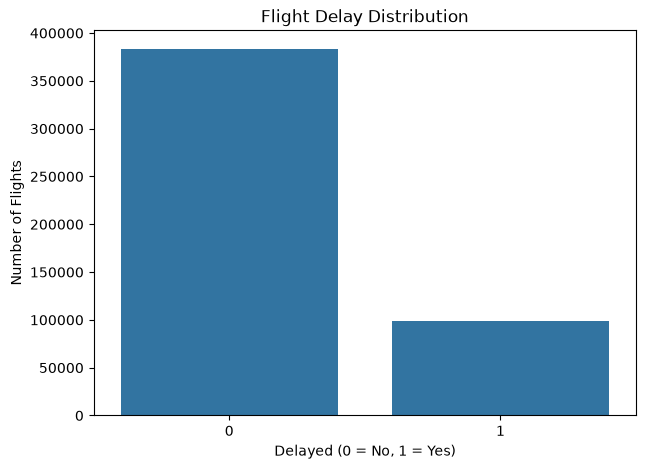

In [26]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df,x="DELAYED")

plt.title("Flight Delay Distribution")
plt.xlabel("Delayed (0 = No, 1 = Yes)")
plt.ylabel("Number of Flights")

plt.show()

## 18. Delay Rate by Airline

We calculate the percentage of delayed flights for each airline.


In [27]:
airline_delay = (df.groupby("AIRLINE")["DELAYED"].mean().sort_values(ascending=False))

print(airline_delay)

AIRLINE
MQ    0.334390
F9    0.322306
NK    0.273303
B6    0.236832
OO    0.235808
EV    0.222280
UA    0.218663
AA    0.212145
WN    0.186789
US    0.182599
VX    0.155064
AS    0.145078
HA    0.130129
DL    0.129080
Name: DELAYED, dtype: float64


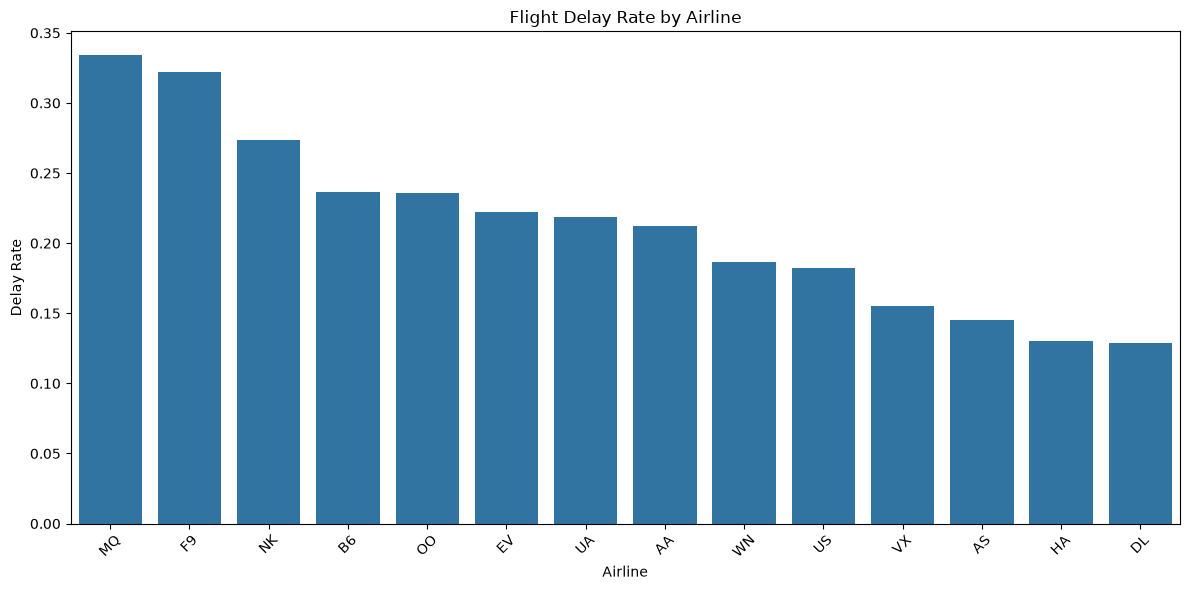

In [28]:
plt.figure(figsize=(12, 6))

sns.barplot(x=airline_delay.index,y=airline_delay.values)

plt.title("Flight Delay Rate by Airline")
plt.xlabel("Airline")
plt.ylabel("Delay Rate")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 19. Delay Rate by Month

We calculate the average delay rate for each month.


In [29]:
monthly_delay = (df.groupby("MONTH")["DELAYED"].mean())

print(monthly_delay)

MONTH
1    0.202198
2    0.245936
Name: DELAYED, dtype: float64


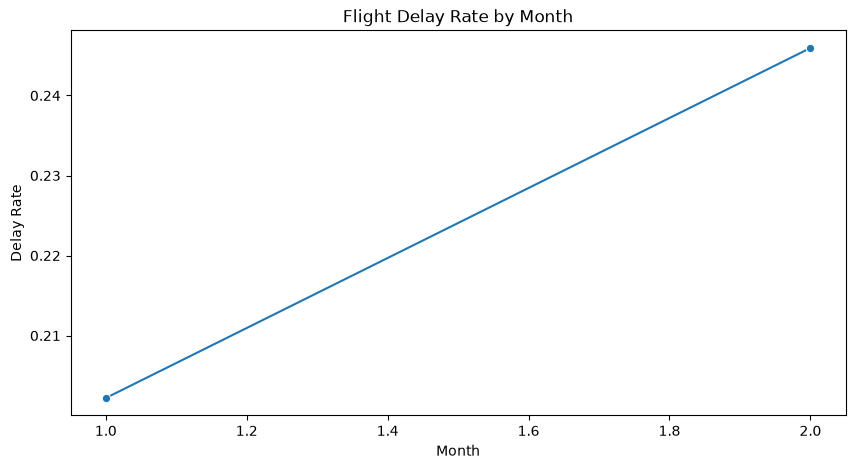

In [30]:
plt.figure(figsize=(10, 5))

sns.lineplot(x=monthly_delay.index,y=monthly_delay.values,marker="o")

plt.title("Flight Delay Rate by Month")
plt.xlabel("Month")
plt.ylabel("Delay Rate")

plt.show()

## 20. Delay Rate by Day of Week

We calculate the delay rate for each day of the week.


In [31]:
weekly_delay = (df.groupby("DAY_OF_WEEK")["DELAYED"].mean())

print(weekly_delay)

DAY_OF_WEEK
1    0.248830
2    0.183251
3    0.164127
4    0.175882
5    0.204037
6    0.196142
7    0.248962
Name: DELAYED, dtype: float64


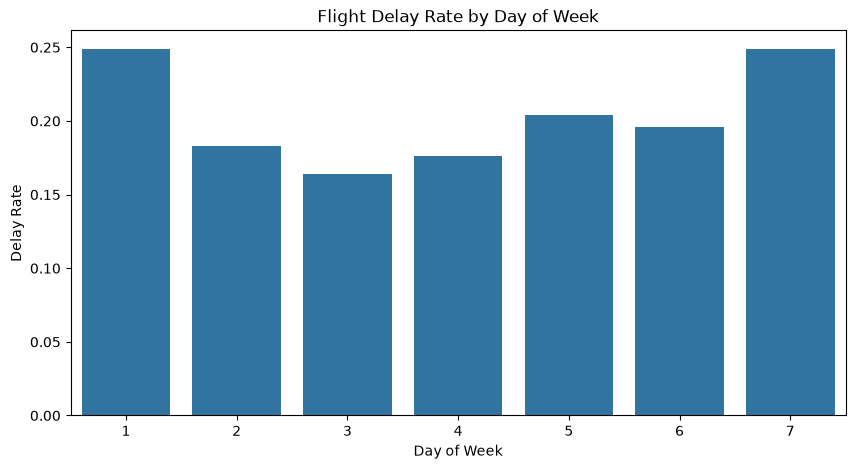

In [32]:
plt.figure(figsize=(10, 5))

sns.barplot(x=weekly_delay.index,y=weekly_delay.values)

plt.title("Flight Delay Rate by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Delay Rate")

plt.show()

## 21. Outlier Analysis

We examine numerical variables using boxplots and the Interquartile Range
(IQR) method.


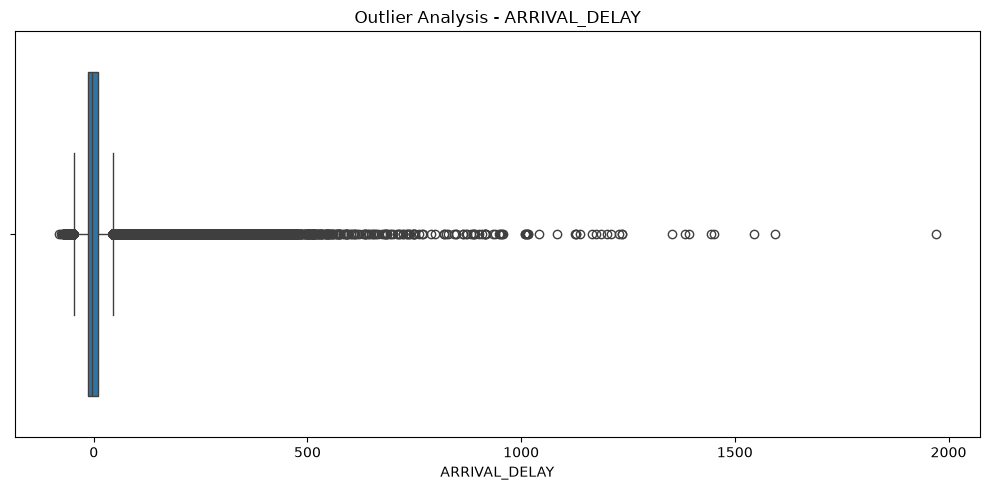

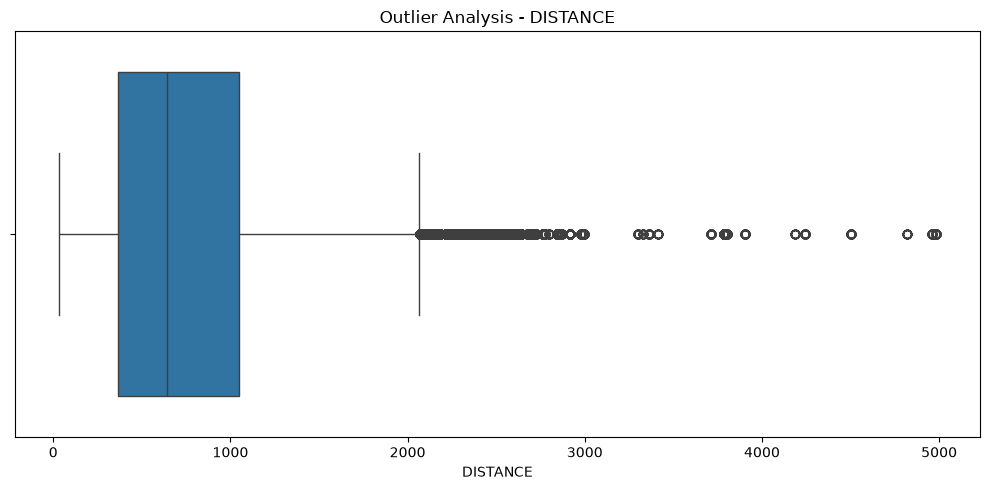

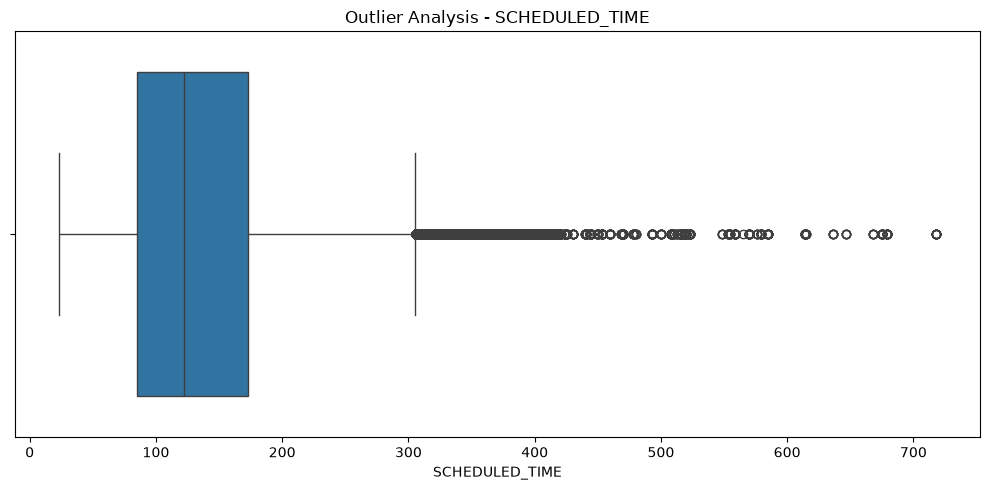

In [33]:
outlier_columns = ["ARRIVAL_DELAY","DISTANCE","SCHEDULED_TIME"]

for column in outlier_columns:

    plt.figure(figsize=(10, 5))

    sns.boxplot(x=df[column].dropna())

    plt.title(f"Outlier Analysis - {column}")

    plt.xlabel(column)

    plt.tight_layout()
    plt.show()

In [34]:
for column in outlier_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = ((df[column] < lower_bound)|(df[column] > upper_bound)).sum()

    print("\nColumn:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Potential Outliers:", outlier_count)


Column: ARRIVAL_DELAY
Q1: -13.0
Q3: 10.0
IQR: 23.0
Lower Bound: -47.5
Upper Bound: 44.5
Potential Outliers: 43310

Column: DISTANCE
Q1: 368.0
Q3: 1047.0
IQR: 679.0
Lower Bound: -650.5
Upper Bound: 2065.5
Potential Outliers: 27882

Column: SCHEDULED_TIME
Q1: 85.0
Q3: 173.0
IQR: 88.0
Lower Bound: -47.0
Upper Bound: 305.0
Potential Outliers: 23167


## 22. Feature Engineering

### What we did
We extract useful information from `SCHEDULED_DEPARTURE`.

Two features are created:

- `DEP_HOUR` — scheduled departure hour
- `DEP_MINUTE` — scheduled departure minute

We also create `DEP_PERIOD`, which categorizes the departure into Night,
Morning, Afternoon, or Evening.

### Why we did it
The original scheduled departure value is stored as HHMM. Separating it into
hour and minute makes the information easier for machine learning algorithms
to use.

In [35]:
df["DEP_HOUR"] = (df["SCHEDULED_DEPARTURE"] // 100)

df["DEP_MINUTE"] = (df["SCHEDULED_DEPARTURE"] % 100)

print(df[["SCHEDULED_DEPARTURE","DEP_HOUR","DEP_MINUTE"]].head())

   SCHEDULED_DEPARTURE  DEP_HOUR  DEP_MINUTE
0                    5         0           5
1                   10         0          10
2                   20         0          20
3                   20         0          20
4                   25         0          25


In [36]:
def get_time_period(hour):

    if hour < 6:
        return "Night"

    elif hour < 12:
        return "Morning"

    elif hour < 18:
        return "Afternoon"

    else:
        return "Evening"


df["DEP_PERIOD"] = (df["DEP_HOUR"].apply(get_time_period))

print(df["DEP_PERIOD"].value_counts())

DEP_PERIOD
Morning      190884
Afternoon    185209
Evening       97819
Night          8140
Name: count, dtype: int64


### Interpretation

The new `DEP_PERIOD` variable groups scheduled departure times into four
time periods. This provides a simpler representation of daily departure
patterns that may help the classification model identify differences in
delay behaviour.

## 23. Feature Selection

### What we did
We select features that are available before a flight departs.

### Why we did it
The purpose is to predict flight delay before departure. Therefore, variables
that are only known after or during the flight must not be used.

### Data leakage prevention

We do not use variables such as:

- DEPARTURE_DELAY
- ARRIVAL_DELAY
- WHEELS_OFF
- WHEELS_ON
- AIR_TIME
- ELAPSED_TIME
- ARRIVAL_TIME
- AIR_SYSTEM_DELAY
- SECURITY_DELAY
- AIRLINE_DELAY
- WEATHER_DELAY

Using these variables could give the model information that would not be
available when making a real pre-flight prediction.

In [37]:
features = ["MONTH","DAY","DAY_OF_WEEK","AIRLINE","ORIGIN_AIRPORT","DESTINATION_AIRPORT","SCHEDULED_TIME","DISTANCE","DEP_HOUR","DEP_MINUTE","DEP_PERIOD"]

X = df[features].copy()
y = df["DELAYED"].copy()

print("Selected features:")
print(X.columns.tolist())

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Selected features:
['MONTH', 'DAY', 'DAY_OF_WEEK', 'AIRLINE', 'ORIGIN_AIRPORT', 'DESTINATION_AIRPORT', 'SCHEDULED_TIME', 'DISTANCE', 'DEP_HOUR', 'DEP_MINUTE', 'DEP_PERIOD']

X shape: (482052, 11)
y shape: (482052,)


## 24. Train-Test Split

### What we did
We divide the data into 80% training data and 20% testing data.

### Why we did it
The training set is used to learn patterns, while the test set is kept
separate to evaluate how well the final models generalize to unseen data.

Stratification is used so that the proportion of delayed and non-delayed
flights remains similar in both sets.

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (385641, 11)
Testing data: (96411, 11)


## 25. Data Preprocessing Pipeline

### What we did
We create separate preprocessing steps for numerical and categorical
variables.

### Numerical variables
Missing values are replaced with the median and values are standardized.

### Categorical variables
Missing values are replaced with the most frequent value and categorical
variables are converted into numerical one-hot encoded features.

### Why we did it
Machine learning algorithms require numerical inputs and some algorithms
benefit from standardized numerical features.

The preprocessing is placed inside a pipeline so that transformations are
learned only from the training data, helping prevent data leakage.

In [39]:
from sklearn.preprocessing import (OneHotEncoder,StandardScaler)

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

In [40]:
categorical_features = ["AIRLINE","ORIGIN_AIRPORT","DESTINATION_AIRPORT","DEP_PERIOD"]

numerical_features = ["MONTH","DAY","DAY_OF_WEEK","SCHEDULED_TIME","DISTANCE","DEP_HOUR","DEP_MINUTE"]

In [41]:
numeric_transformer = Pipeline(steps=[("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())])

categorical_transformer = Pipeline(steps=[("imputer",SimpleImputer(strategy="most_frequent")),("encoder",OneHotEncoder(handle_unknown="ignore"))])

preprocessor = ColumnTransformer(transformers=[("num",numeric_transformer,numerical_features),("cat",categorical_transformer,categorical_features)])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 26. Model 1 — Logistic Regression

### What we did
We train a Logistic Regression classifier.

### Why we did it
Logistic Regression is a suitable baseline algorithm for binary classification.
It estimates the probability that a flight belongs to the delayed class.

### Regularization
Logistic Regression includes L2 regularization by default in Scikit-learn.
Regularization helps control model complexity and reduce overfitting.

In [42]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[("preprocessor",preprocessor),("classifier",LogisticRegression(max_iter=1000,class_weight="balanced"))])

logistic_model.fit(X_train,y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [43]:
y_pred_lr = logistic_model.predict(X_test)

y_prob_lr = (logistic_model.predict_proba(X_test)[:, 1])

## 27. Model 2 — Decision Tree

### What we did
We train a Decision Tree classifier.

### Why we did it
Decision Trees can model nonlinear relationships and are easy to interpret.
They can split flights based on features such as airline, departure time,
distance, and airport.

The tree depth is restricted to help reduce overfitting.

In [44]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline(steps=[("preprocessor",preprocessor),("classifier",DecisionTreeClassifier(max_depth=15,min_samples_split=20,random_state=42,class_weight="balanced"))])

decision_tree_model.fit(X_train,y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [45]:
y_pred_dt = (decision_tree_model.predict(X_test))

y_prob_dt = (decision_tree_model.predict_proba(X_test)[:, 1])

## 28. Model 3 — Random Forest

### What we did
We train a Random Forest classifier containing multiple decision trees.

### Why we did it
Random Forest combines predictions from many trees and can capture complex
relationships while generally being more robust than a single decision tree.

Class weighting is used because the target classes may not be perfectly
balanced.

In [46]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[("preprocessor",preprocessor),("classifier",RandomForestClassifier(n_estimators=100,max_depth=15,min_samples_split=20,random_state=42,n_jobs=-1,class_weight="balanced"))])

random_forest_model.fit(X_train,y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [47]:
y_pred_rf = (random_forest_model.predict(X_test))

y_prob_rf = (random_forest_model.predict_proba(X_test)[:, 1])

## 29. Model 4 — Gradient Boosting

### What we did
We train a Gradient Boosting classifier.

### Why we did it
Gradient Boosting builds trees sequentially, with each new tree attempting
to improve errors made by the previous trees. It can model nonlinear
relationships effectively.

In [48]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=5,
                random_state=42
            )
        )
    ]
)

gradient_boosting_model.fit(
    X_train,
    y_train
)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [49]:
y_pred_gb = (gradient_boosting_model.predict(X_test))

y_prob_gb = (gradient_boosting_model.predict_proba(X_test)[:, 1])

## 30. Model 5 — XGBoost

### What we did
We train an XGBoost classifier.

### Why we did it
XGBoost is an advanced gradient-boosting algorithm that can model complex
relationships and often performs strongly on structured tabular datasets.

It is included as the advanced algorithm in this project.

In [50]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=100,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

xgb_model.fit(
    X_train,
    y_train
)

print(
    "XGBoost trained successfully!"
)

XGBoost trained successfully!


In [51]:
y_pred_xgb = (xgb_model.predict(X_test))

y_prob_xgb = (xgb_model.predict_proba(X_test)[:, 1])

## 31. Initial Model Evaluation

### What we did
We evaluate all five models using Accuracy, Precision, Recall, F1-score,
and ROC-AUC.

### Why we did it
Using several metrics gives a more complete view of model performance.

F1-score is particularly important because it balances precision and recall.
ROC-AUC measures the ability of the model to distinguish between the two
classes across classification thresholds.

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb),
        f1_score(y_test, y_pred_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb),
        roc_auc_score(y_test, y_prob_xgb)
    ]
})

print(
    results.round(4).to_string(index=False)
)

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.6360     0.3131  0.6536    0.4234   0.6946
      Decision Tree    0.7174     0.3820  0.6185    0.4723   0.7374
      Random Forest    0.6927     0.3543  0.6115    0.4486   0.7224
  Gradient Boosting    0.8159     0.6948  0.1774    0.2826   0.7549
            XGBoost    0.8185     0.7070  0.1917    0.3016   0.7648


## 32. 5-Fold Stratified Cross-Validation

### What we did
We use 5-fold Stratified Cross-Validation and calculate the mean F1-score.

### Why we did it
A single train-test split can produce a performance estimate that depends
on which observations happened to be placed in the test set.

Cross-validation evaluates the models across several training and validation
splits and therefore provides a more reliable estimate of performance.

Stratification maintains the class distribution in each fold.

In [ ]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model,
    "XGBoost": xgb_model
}

cv_results = []

for name, model in models.items():

    print(
        f"Cross-validating {name}..."
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Std CV F1": scores.std()
    })

cv_results_df = pd.DataFrame(
    cv_results
)

print("\nCross-Validation Results:")
print(
    cv_results_df
    .round(4)
    .to_string(index=False)
)

Cross-validating Logistic Regression...
Cross-validating Decision Tree...
Cross-validating Random Forest...
Cross-validating Gradient Boosting...


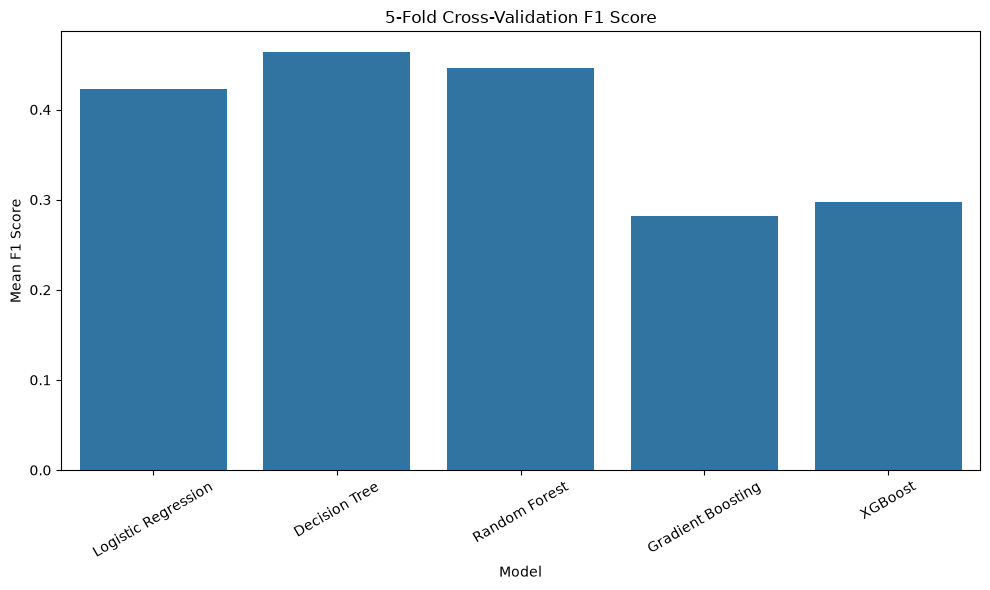

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_results_df,
    x="Model",
    y="Mean CV F1"
)

plt.title(
    "5-Fold Cross-Validation F1 Score"
)

plt.xlabel("Model")
plt.ylabel("Mean F1 Score")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## 33. Hyperparameter Tuning — Random Forest

### What we did
We use RandomizedSearchCV to search for better Random Forest hyperparameters.

### Why we did it
Random Forest performance depends on parameters such as number of trees,
tree depth, minimum samples, and number of features considered at each split.

RandomizedSearchCV evaluates several parameter combinations using
cross-validation.

### Evaluation metric
F1-score is used because both precision and recall are important for the
flight-delay classification task.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)

In [ ]:
rf_param_grid = {

    "classifier__n_estimators": [
        100,
        200,
        300
    ],

    "classifier__max_depth": [
        10,
        15,
        20,
        None
    ],

    "classifier__min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "classifier__min_samples_leaf": [
        1,
        2,
        4
    ],

    "classifier__max_features": [
        "sqrt",
        "log2"
    ]
}

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# Faster Random Forest pipeline
rf_pipeline_fast = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            RandomForestClassifier(
                random_state=42,
                n_jobs=-1,
                class_weight="balanced"
            )
        )
    ]
)

# Smaller parameter search
rf_param_grid_fast = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 15],
    "classifier__min_samples_split": [5, 10]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline_fast,
    param_distributions=rf_param_grid_fast,
    n_iter=3,              # only 3 combinations
    scoring="f1",
    cv=2,                  # 2-fold instead of 3-fold
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("Starting faster Random Forest tuning...")

rf_random_search.fit(
    X_train,
    y_train
)

print("\nRandom Forest tuning completed!")

print("\nBest Parameters:")
print(rf_random_search.best_params_)

print("\nBest CV F1 Score:")
print(round(rf_random_search.best_score_, 4))

Starting faster Random Forest tuning...
Fitting 2 folds for each of 3 candidates, totalling 6 fits

Random Forest tuning completed!

Best Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_depth': 15}

Best CV F1 Score:
0.4443


In [ ]:
print("Best Random Forest Parameters:")
print(rf_random_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(rf_random_search.best_score_, 4))

Best Random Forest Parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__max_depth': 15}

Best Cross-Validation F1 Score:
0.4443


## 34. Evaluate Tuned Random Forest

### What we did
We use the tuned Random Forest to make predictions on the test dataset.

### Why we did it
The test dataset was not used during hyperparameter tuning. Therefore,
it provides an independent evaluation of how well the tuned model performs
on unseen data.

### Metrics
We calculate:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

rf_tuned_pred = rf_random_search.predict(X_test)

rf_tuned_prob = (
    rf_random_search.predict_proba(X_test)[:, 1]
)

rf_tuned_accuracy = accuracy_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_precision = precision_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_recall = recall_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_f1 = f1_score(
    y_test,
    rf_tuned_pred
)

rf_tuned_auc = roc_auc_score(
    y_test,
    rf_tuned_prob
)

print("Tuned Random Forest Results")
print("--------------------------------")
print("Accuracy :", round(rf_tuned_accuracy, 4))
print("Precision:", round(rf_tuned_precision, 4))
print("Recall   :", round(rf_tuned_recall, 4))
print("F1 Score :", round(rf_tuned_f1, 4))
print("ROC-AUC  :", round(rf_tuned_auc, 4))

Tuned Random Forest Results
--------------------------------
Accuracy : 0.6926
Precision: 0.354
Recall   : 0.6104
F1 Score : 0.4482
ROC-AUC  : 0.7217


## 35. Confusion Matrix — Tuned Random Forest

### What we did
We create a confusion matrix for the tuned Random Forest.

### Why we did it
The confusion matrix allows us to see how many flights were correctly and
incorrectly classified as delayed or not delayed.

### Interpretation

- True Negative: correctly predicted not delayed
- True Positive: correctly predicted delayed
- False Positive: predicted delayed but actually not delayed
- False Negative: predicted not delayed but actually delayed

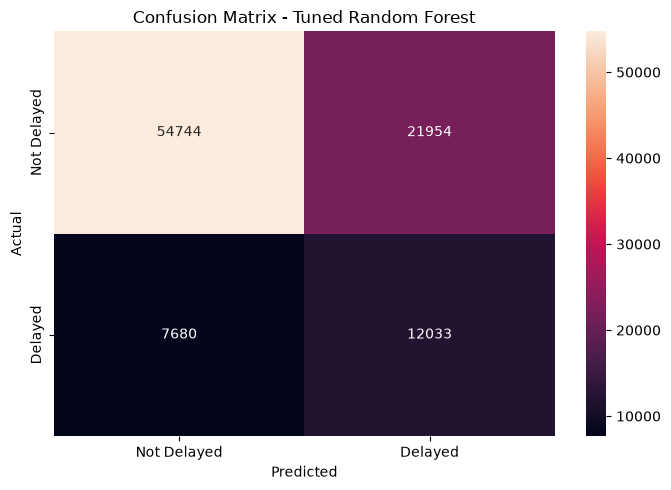

In [ ]:
from sklearn.metrics import confusion_matrix

cm_rf = confusion_matrix(
    y_test,
    rf_tuned_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    xticklabels=["Not Delayed", "Delayed"],
    yticklabels=["Not Delayed", "Delayed"]
)

plt.title("Confusion Matrix - Tuned Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

## 36. Classification Report — Tuned Random Forest

### What we did
We generate the complete classification report.

### Why we did it
The classification report provides precision, recall, F1-score, and support
for both classes separately.

This gives more detailed information than accuracy alone.

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        rf_tuned_pred,
        target_names=[
            "Not Delayed",
            "Delayed"
        ]
    )
)

              precision    recall  f1-score   support

 Not Delayed       0.88      0.71      0.79     76698
     Delayed       0.35      0.61      0.45     19713

    accuracy                           0.69     96411
   macro avg       0.62      0.66      0.62     96411
weighted avg       0.77      0.69      0.72     96411



## 37. Install XGBoost

### What we did
We install the XGBoost library.

### Why we did it
XGBoost is an advanced gradient boosting algorithm and is the fifth major
algorithm used in this project.

## 38. Import XGBoost

### What we did
We import XGBClassifier.

### Why we did it
XGBClassifier is used for binary classification of flights into delayed
and not delayed categories.

In [ ]:
from xgboost import XGBClassifier

print("XGBoost imported successfully!")

XGBoost imported successfully!


## 39. XGBoost Pipeline

### What we did
We create a machine learning pipeline containing the existing preprocessing
steps and an XGBoost classifier.

### Why we did it
Using a pipeline ensures that preprocessing is performed consistently before
the XGBoost model receives the data.

XGBoost is suitable for this project because it can learn complex nonlinear
relationships in structured/tabular data.

In [ ]:
xgb_pipeline = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                n_estimators=100,
                max_depth=6,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

print("XGBoost pipeline created successfully!")

XGBoost pipeline created successfully!


## 40. Train XGBoost

### What we did
We train the XGBoost classifier using the training dataset.

### Why we did it
This allows XGBoost to learn the relationship between the pre-departure
flight features and the delayed/not-delayed target.

### Expected output
The message confirms that the model has finished training.

In [ ]:
print("Training XGBoost...")

xgb_pipeline.fit(
    X_train,
    y_train
)

print("XGBoost training completed!")


Training XGBoost...
XGBoost training completed!


## 41. XGBoost Predictions

### What we did
We generate class predictions and delay probabilities for the test set.

### Why we did it
The predictions are required to calculate the evaluation metrics.

In [ ]:
y_pred_xgb = xgb_pipeline.predict(
    X_test
)

y_prob_xgb = (
    xgb_pipeline
    .predict_proba(X_test)[:, 1]
)

print("XGBoost predictions generated!")

XGBoost predictions generated!


## 42. Evaluate XGBoost

### What we did
We calculate Accuracy, Precision, Recall, F1-score, and ROC-AUC.

### Why we did it
These metrics allow us to compare XGBoost with the other machine learning
algorithms used in the project.

In [ ]:
xgb_accuracy = accuracy_score(
    y_test,
    y_pred_xgb
)

xgb_precision = precision_score(
    y_test,
    y_pred_xgb
)

xgb_recall = recall_score(
    y_test,
    y_pred_xgb
)

xgb_f1 = f1_score(
    y_test,
    y_pred_xgb
)

xgb_auc = roc_auc_score(
    y_test,
    y_prob_xgb
)

print("XGBoost Results")
print("----------------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("ROC-AUC  :", round(xgb_auc, 4))


XGBoost Results
----------------------
Accuracy : 0.8185
Precision: 0.707
Recall   : 0.1917
F1 Score : 0.3016
ROC-AUC  : 0.7648


## 43. XGBoost Hyperparameter Tuning

### What we did
We use RandomizedSearchCV to search for a better combination of XGBoost
hyperparameters.

### Why we did it
Hyperparameter tuning can improve model performance by finding a suitable
learning rate, tree depth, number of estimators, and sampling parameters.

### Performance consideration
Because the dataset is large, only a small number of combinations and two
cross-validation folds are used. This provides tuning while keeping the
execution time manageable in VS Code.

In [ ]:
xgb_pipeline_fast = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            XGBClassifier(
                random_state=42,
                eval_metric="logloss",
                n_jobs=-1
            )
        )
    ]
)

xgb_param_grid_fast = {

    "classifier__n_estimators": [
        50,
        100
    ],

    "classifier__max_depth": [
        3,
        6
    ],

    "classifier__learning_rate": [
        0.05,
        0.1
    ],

    "classifier__subsample": [
        0.8,
        1.0
    ]
}

print("XGBoost tuning configuration created!")

XGBoost tuning configuration created!


## 44. Create a Smaller Tuning Dataset

### What we did
We select 100,000 training records for hyperparameter tuning.

### Why we did it
The complete training dataset contains a large number of observations.
Using a representative subset makes the hyperparameter search considerably
faster.

The final evaluation will still be performed using the untouched test set.

In [ ]:
X_tune_xgb, _, y_tune_xgb, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("XGBoost tuning data:")
print("X:", X_tune_xgb.shape)
print("y:", y_tune_xgb.shape)

XGBoost tuning data:
X: (100000, 11)
y: (100000,)


## 45. Run XGBoost Hyperparameter Tuning

### What we did
We perform RandomizedSearchCV using two-fold cross-validation and a small
number of parameter combinations.

### Why we did it
This satisfies the hyperparameter tuning requirement while reducing the
computational cost for the large flight dataset.

### What the output means
The output shows the progress of the parameter search and the number of
model fits performed.

In [ ]:
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline_fast,
    param_distributions=xgb_param_grid_fast,
    n_iter=3,
    scoring="f1",
    cv=2,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

print("Starting faster XGBoost tuning...")

xgb_random_search.fit(
    X_tune_xgb,
    y_tune_xgb
)

print("\nXGBoost tuning completed!")

Starting faster XGBoost tuning...
Fitting 2 folds for each of 3 candidates, totalling 6 fits

XGBoost tuning completed!


## 46. Best XGBoost Parameters

### What we did
We display the parameter combination that achieved the highest
cross-validation F1-score.

### Why we did it
These parameters represent the best configuration found during our limited
hyperparameter search.

In [ ]:
print("Best XGBoost Parameters:")
print(
    xgb_random_search.best_params_
)

print("\nBest Cross-Validation F1 Score:")
print(
    round(
        xgb_random_search.best_score_,
        4
    )
)

Best XGBoost Parameters:
{'classifier__subsample': 1.0, 'classifier__n_estimators': 50, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.05}

Best Cross-Validation F1 Score:
0.2113


## 47. Evaluate Tuned XGBoost

### What we did
We use the tuned XGBoost model to predict the untouched test dataset.

### Why we did it
The test data was not used during hyperparameter tuning, making it suitable
for evaluating the generalization performance of the tuned model.

In [ ]:
xgb_tuned_pred = (
    xgb_random_search
    .predict(X_test)
)

xgb_tuned_prob = (
    xgb_random_search
    .predict_proba(X_test)[:, 1]
)

xgb_tuned_accuracy = accuracy_score(
    y_test,
    xgb_tuned_pred
)

xgb_tuned_precision = precision_score(
    y_test,
    xgb_tuned_pred
)

xgb_tuned_recall = recall_score(
    y_test,
    xgb_tuned_pred
)

xgb_tuned_f1 = f1_score(
    y_test,
    xgb_tuned_pred
)

xgb_tuned_auc = roc_auc_score(
    y_test,
    xgb_tuned_prob
)

print("Tuned XGBoost Results")
print("-------------------------")
print("Accuracy :", round(xgb_tuned_accuracy, 4))
print("Precision:", round(xgb_tuned_precision, 4))
print("Recall   :", round(xgb_tuned_recall, 4))
print("F1 Score :", round(xgb_tuned_f1, 4))
print("ROC-AUC  :", round(xgb_tuned_auc, 4))

Tuned XGBoost Results
-------------------------
Accuracy : 0.8108
Precision: 0.7231
Recall   : 0.1209
F1 Score : 0.2072
ROC-AUC  : 0.7368


## 48. Final Model Comparison

### What we did
We create a single table containing the evaluation results of all models.

### Why we did it
Comparing all models using the same metrics allows us to objectively select
the best model.

### Models compared

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Gradient Boosting
5. XGBoost
6. Tuned Random Forest
7. Tuned XGBoost

The tuned models are additional improved versions of Random Forest and
XGBoost.

In [ ]:
final_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "XGBoost",
        "Tuned Random Forest",
        "Tuned XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        xgb_accuracy,
        rf_tuned_accuracy,
        xgb_tuned_accuracy
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_gb),
        xgb_precision,
        rf_tuned_precision,
        xgb_tuned_precision
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_gb),
        xgb_recall,
        rf_tuned_recall,
        xgb_tuned_recall
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gb),
        xgb_f1,
        rf_tuned_f1,
        xgb_tuned_f1
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_gb),
        xgb_auc,
        rf_tuned_auc,
        xgb_tuned_auc
    ]
})

print(
    final_results.round(4).to_string(index=False)
)

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression    0.6360     0.3131  0.6536    0.4234   0.6946
      Decision Tree    0.7174     0.3820  0.6185    0.4723   0.7374
      Random Forest    0.6927     0.3543  0.6115    0.4486   0.7224
  Gradient Boosting    0.8159     0.6948  0.1774    0.2826   0.7549
            XGBoost    0.8185     0.7070  0.1917    0.3016   0.7648
Tuned Random Forest    0.6926     0.3540  0.6104    0.4482   0.7217
      Tuned XGBoost    0.8108     0.7231  0.1209    0.2072   0.7368


## 49. Rank the Models

### What we did
We sort the models according to their F1-score from highest to lowest.

### Why we did it
F1-score is our primary metric because it balances precision and recall.
The highest F1-score indicates the strongest balance between identifying
delayed flights and avoiding incorrect delay predictions.

In [ ]:
final_results_sorted = (
    final_results
    .sort_values(
        by="F1 Score",
        ascending=False
    )
    .reset_index(drop=True)
)

print(
    final_results_sorted
    .round(4)
    .to_string(index=False)
)

              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
      Decision Tree    0.7174     0.3820  0.6185    0.4723   0.7374
      Random Forest    0.6927     0.3543  0.6115    0.4486   0.7224
Tuned Random Forest    0.6926     0.3540  0.6104    0.4482   0.7217
Logistic Regression    0.6360     0.3131  0.6536    0.4234   0.6946
            XGBoost    0.8185     0.7070  0.1917    0.3016   0.7648
  Gradient Boosting    0.8159     0.6948  0.1774    0.2826   0.7549
      Tuned XGBoost    0.8108     0.7231  0.1209    0.2072   0.7368


## 50. Select the Best Model

### What we did
We automatically select the model with the highest F1-score.

### Why we did it
Instead of manually assuming that one algorithm is best, the actual
experimental results determine the final model.

In [ ]:
best_model_name = (
    final_results_sorted
    .iloc[0]["Model"]
)

print(
    "Best Model:",
    best_model_name
)

Best Model: Decision Tree


## 51. Store the Best Model

### What we did
We create a dictionary containing all trained models and select the model
identified as the best performer.

### Why we did it
The selected model will be used for confusion-matrix analysis, unseen
flight prediction, and saving the final model.

In [ ]:
final_models = {

    "Logistic Regression":
        logistic_model,

    "Decision Tree":
        decision_tree_model,

    "Random Forest":
        random_forest_model,

    "Gradient Boosting":
        gradient_boosting_model,

    "XGBoost":
        xgb_pipeline,

    "Tuned Random Forest":
        rf_random_search,

    "Tuned XGBoost":
        xgb_random_search
}

best_model = final_models[
    best_model_name
]

print(
    "Selected final model:",
    best_model_name
)

Selected final model: Decision Tree


## 52. Final Model Performance

### What we did
We display the performance metrics of the selected model.

### Why we did it
These values will be used in the final project report to justify why this
model was selected.

In [ ]:
best_row = (
    final_results_sorted
    .iloc[0]
)

print("========== FINAL MODEL ==========")

print(
    "Model     :",
    best_row["Model"]
)

print(
    "Accuracy  :",
    round(best_row["Accuracy"], 4)
)

print(
    "Precision :",
    round(best_row["Precision"], 4)
)

print(
    "Recall    :",
    round(best_row["Recall"], 4)
)

print(
    "F1 Score  :",
    round(best_row["F1 Score"], 4)
)

print(
    "ROC-AUC   :",
    round(best_row["ROC-AUC"], 4)
)

========== FINAL MODEL ==========
Model     : Decision Tree
Accuracy  : 0.7174
Precision : 0.382
Recall    : 0.6185
F1 Score  : 0.4723
ROC-AUC   : 0.7374


## 53. Model Comparison — F1 Score

### What we did
We visualize the F1-score of all models.

### Why we did it
A graphical comparison makes it easier to identify which model achieved the
best balance between precision and recall.

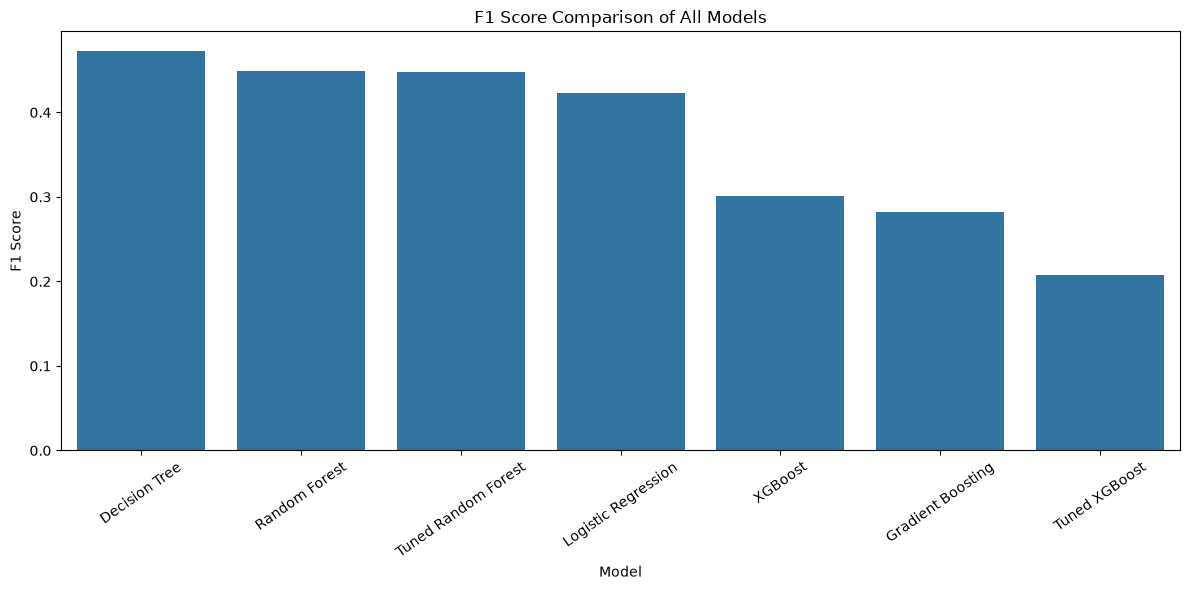

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=final_results_sorted,
    x="Model",
    y="F1 Score"
)

plt.title("F1 Score Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

## 54. Model Comparison — Accuracy

### What we did
We compare the accuracy of all candidate models.

### Why we did it
Accuracy shows the overall proportion of correctly classified flights.
However, it is not considered alone because the dataset may have unequal
class distributions.

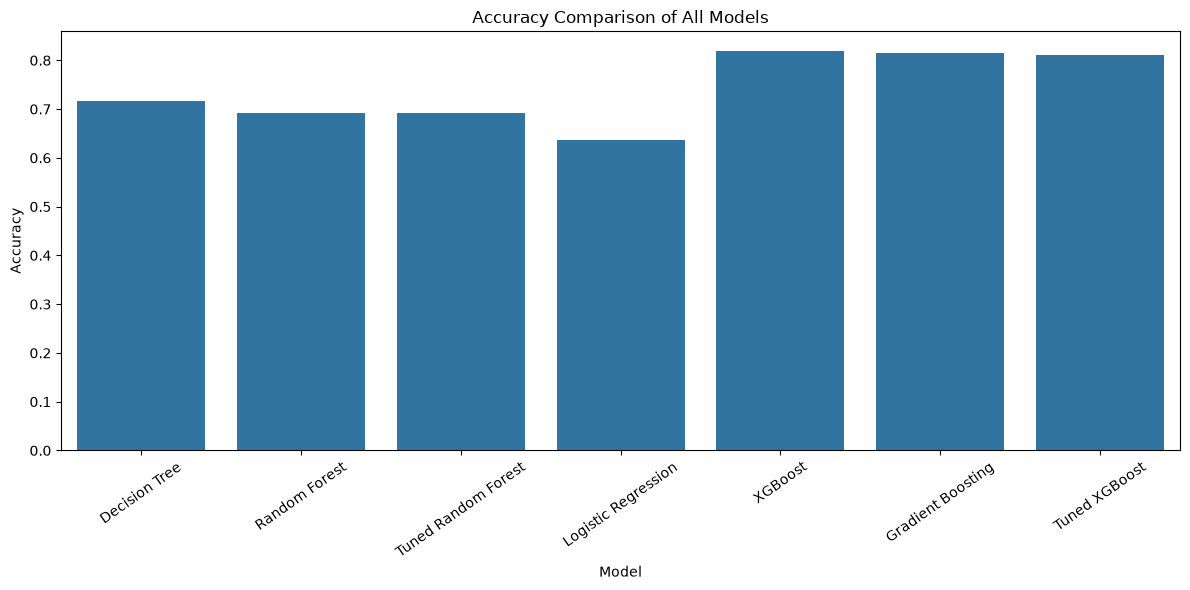

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=final_results_sorted,
    x="Model",
    y="Accuracy"
)

plt.title("Accuracy Comparison of All Models")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

## 55. Confusion Matrix — Final Model

### What we did
We generate the confusion matrix using the automatically selected final
model.

### Why we did it
This provides a detailed view of the final model's classification errors.

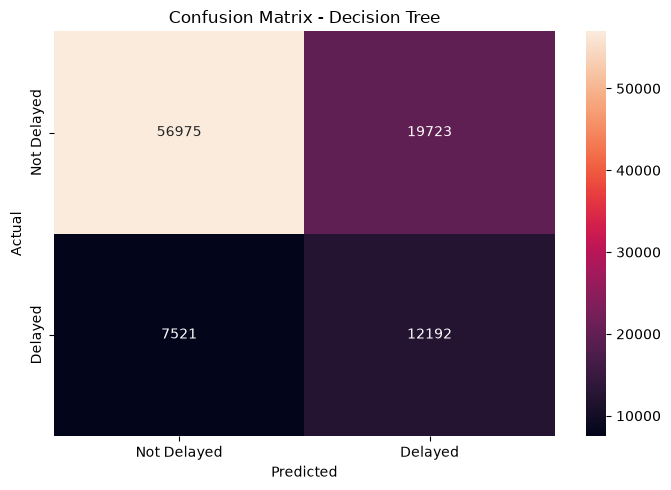

In [ ]:
best_pred = best_model.predict(
    X_test
)

cm = confusion_matrix(
    y_test,
    best_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=[
        "Not Delayed",
        "Delayed"
    ],
    yticklabels=[
        "Not Delayed",
        "Delayed"
    ]
)

plt.title(
    f"Confusion Matrix - {best_model_name}"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

## 56. Final Classification Report

### What we did
We generate the classification report for the selected model.

### Why we did it
The report gives precision, recall, and F1-score separately for the
not-delayed and delayed classes.

In [ ]:
print(
    classification_report(
        y_test,
        best_pred,
        target_names=[
            "Not Delayed",
            "Delayed"
        ]
    )
)


              precision    recall  f1-score   support

 Not Delayed       0.88      0.74      0.81     76698
     Delayed       0.38      0.62      0.47     19713

    accuracy                           0.72     96411
   macro avg       0.63      0.68      0.64     96411
weighted avg       0.78      0.72      0.74     96411



## 57. ROC Curve — Final Model

### What we did
We plot the ROC curve for the final selected model.

### Why we did it
The ROC curve evaluates how well the model separates delayed and
not-delayed flights across different classification thresholds.

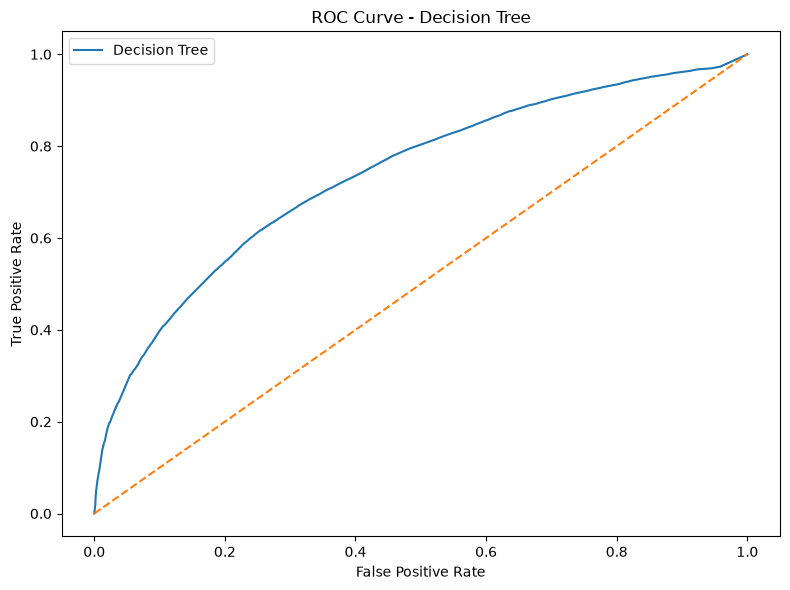

In [ ]:
from sklearn.metrics import roc_curve

best_probability = (
    best_model
    .predict_proba(X_test)[:, 1]
)

fpr, tpr, thresholds = roc_curve(
    y_test,
    best_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"{best_model_name}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title(
    f"ROC Curve - {best_model_name}"
)

plt.legend()

plt.tight_layout()
plt.show()

## 58. Prediction on New / Unseen Flight

### What we did
We create a new flight record that was not part of the training or testing
datasets.

### Why we did it
A real machine learning system should be able to use the trained model to
predict the outcome for a previously unseen flight.

### Important
Only information available before departure is used. Actual arrival delay
and departure delay are not provided to the model because they would not be
known at prediction time.

In [ ]:
new_flight = pd.DataFrame({

    "MONTH": [7],

    "DAY": [15],

    "DAY_OF_WEEK": [3],

    "AIRLINE": ["AA"],

    "ORIGIN_AIRPORT": ["JFK"],

    "DESTINATION_AIRPORT": ["LAX"],

    "SCHEDULED_TIME": [360],

    "DISTANCE": [2475],

    "DEP_HOUR": [18],

    "DEP_MINUTE": [30],

    "DEP_PERIOD": ["Evening"]
})

print("New Flight Details:")
print(new_flight)

New Flight Details:
   MONTH  DAY  DAY_OF_WEEK AIRLINE ORIGIN_AIRPORT DESTINATION_AIRPORT  \
0      7   15            3      AA            JFK                 LAX   

   SCHEDULED_TIME  DISTANCE  DEP_HOUR  DEP_MINUTE DEP_PERIOD  
0             360      2475        18          30    Evening  


## 59. Predict the New Flight

### What we did
We use the selected final model to predict whether the new flight will be
delayed.

### Why we did it
This demonstrates the practical application of the trained machine learning
system.

### Output

- 0 = Not Delayed
- 1 = Delayed

The probability represents the model's estimated probability that the flight
belongs to the delayed class.

In [ ]:
new_prediction = (
    best_model
    .predict(new_flight)[0]
)

new_probability = (
    best_model
    .predict_proba(new_flight)[0][1]
)

print("========== NEW FLIGHT PREDICTION ==========")

if new_prediction == 1:

    print("Prediction: FLIGHT DELAYED")

else:

    print("Prediction: FLIGHT NOT DELAYED")

print(
    "Probability of Delay:",
    round(
        new_probability * 100,
        2
    ),
    "%"
)

========== NEW FLIGHT PREDICTION ==========
Prediction: FLIGHT NOT DELAYED
Probability of Delay: 35.32 %


In [ ]:
import joblib

joblib.dump(
    best_model,
    "flight_delay_final_model.pkl"
)

print(
    "Final model saved successfully!"
)

print(
    "File: flight_delay_final_model.pkl"
)


Final model saved successfully!
File: flight_delay_final_model.pkl


## 60. Verify the Saved Model

We check whether the final model file was successfully created and exists in the project folder.


In [ ]:
import os

model_file = "flight_delay_final_model.pkl"

if os.path.exists(model_file):
    print("Model file exists!")
    print("File:", model_file)
    print("Size:", round(os.path.getsize(model_file) / 1024, 2), "KB")
else:
    print("Model file was not found.")

Model file exists!
File: flight_delay_final_model.pkl
Size: 589.55 KB


## 61. Reload and Test the Saved Model
We reload the saved model and use it to predict the previously created unseen flight.


In [ ]:
loaded_model = joblib.load(
    "flight_delay_final_model.pkl"
)

loaded_prediction = loaded_model.predict(
    new_flight
)[0]

loaded_probability = loaded_model.predict_proba(
    new_flight
)[0][1]

print("Saved model loaded successfully!")

if loaded_prediction == 1:
    print("Prediction: FLIGHT DELAYED")
else:
    print("Prediction: FLIGHT NOT DELAYED")

print(
    "Probability of Delay:",
    round(loaded_probability * 100, 2),
    "%"
)

Saved model loaded successfully!
Prediction: FLIGHT NOT DELAYED
Probability of Delay: 35.32 %


## 62. Final Model Summary

We summarize the selected model and its final evaluation metrics.


In [ ]:
print("======================================")
print("       FINAL MODEL SUMMARY")
print("======================================")

print("Best Model :", best_row["Model"])
print("Accuracy   :", round(best_row["Accuracy"], 4))
print("Precision  :", round(best_row["Precision"], 4))
print("Recall     :", round(best_row["Recall"], 4))
print("F1 Score   :", round(best_row["F1 Score"], 4))
print("ROC-AUC    :", round(best_row["ROC-AUC"], 4))

print("======================================")

       FINAL MODEL SUMMARY
Best Model : Decision Tree
Accuracy   : 0.7174
Precision  : 0.382
Recall     : 0.6185
F1 Score   : 0.4723
ROC-AUC    : 0.7374


## 63. Final Conclusion

The Flight Delay Prediction project followed a complete machine learning workflow from dataset understanding and exploratory data analysis to preprocessing, feature engineering, model training, model comparison, tuning, evaluation, and prediction on unseen data.

### Final Result
Multiple machine learning algorithms were trained and evaluated using appropriate classification metrics. The best-performing model was selected based on the overall evaluation results, with particular attention to the F1-score and ROC-AUC.

The final model was saved as `flight_delay_final_model.pkl` and successfully reloaded for prediction on a new unseen flight.

### Conclusion
The developed machine learning system can be used to predict whether a flight is likely to be delayed using information available before departure. This demonstrates the practical application of machine learning for flight delay prediction.